In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


# Binary-majority variance for a complete graph-IQP circuit

This self-contained experiment evaluates a two-action deterministic-majority
Born policy for
\(n\in\{4,6,8,10,12,14,16\}\). Every circuit is instantiated with QASP's
native `IQPAnsatz` and executed through PennyLane `lightning.qubit`.

**Contents**

1. [Circuit and decoder](#circuit-and-decoder)
2. [Exact variance prediction](#exact-variance-prediction)
3. [Representative QASP circuit](#representative-qasp-circuit)
4. [Monte Carlo experiment](#monte-carlo-experiment)
5. [Variance plot](#variance-plot)
6. [Validation and reproducibility](#validation-and-reproducibility)

In [1]:
from pathlib import Path
import hashlib
import json
import importlib.metadata as importlib_metadata
import platform
import subprocess
import sys
import time

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
import qasp
from IPython.display import display
from qasp.circuits import CircuitBuilder, IQPAnsatz

QUBITS = [4, 6, 8, 10, 12, 14, 16]
N_SAMPLES = 2_000
BASE_SEED = 20261022
FIGURE_DPI = 300
DEVICE = "lightning.qubit"

# The notebook is expected to run from QASP/tests. This fallback also works
# when the kernel starts in the repository root.
cwd = Path.cwd().resolve()
if cwd.name == "tests" and (cwd.parent / "qasp").is_dir():
    PROJECT_ROOT = cwd.parent
    NOTEBOOK_DIR = cwd
elif (cwd / "qasp").is_dir() and (cwd / "tests").is_dir():
    PROJECT_ROOT = cwd
    NOTEBOOK_DIR = cwd / "tests"
else:
    raise RuntimeError("Run this notebook from the QASP repository or QASP/tests directory.")

RESULTS_DIR = NOTEBOOK_DIR / "results" / "iqp_majority_all_to_all_variance"
FIGURES_DIR = RESULTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": FIGURE_DPI,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

try:
    QASP_VERSION = importlib_metadata.version("qasp")
except importlib_metadata.PackageNotFoundError:
    QASP_VERSION = "local checkout"

print(f"QASP: {QASP_VERSION}")
print(f"PennyLane: {qml.__version__}")
print(f"Device: {DEVICE}; samples per n: {N_SAMPLES}")
print(f"Results: {RESULTS_DIR}")

QASP: 0.1.0
PennyLane: 0.42.2
Device: lightning.qubit; samples per n: 2000
Results: ./tests/results/iqp_majority_all_to_all_variance


<a id="circuit-and-decoder"></a>
## Circuit and decoder

For each even \(n\), QASP constructs the one-layer commuting circuit

\[
U(\boldsymbol\alpha,\boldsymbol\beta)
=H^{\otimes n}
  \left[\prod_{i=1}^{n}R_{Z_i}(\alpha_i)\right]
  \left[\prod_{1\leq i<j\leq n}R_{Z_iZ_j}(\beta_{ij})\right]
  H^{\otimes n}.
\]

Thus, `all_to_all` means one \(R_{ZZ}\) generator for every unordered
pair \(i<j\), for a total of \(\binom n2\) two-qubit gates. Writing both
\((i,j)\) and \((j,i)\) would duplicate the same commuting generator.

With \(|A|=2\), majority-modulo has one majority block containing all
qubits. We use QASP's deterministic even-block convention:

\[
a(x)=\begin{cases}
0,& |x|\le n/2,\\
1,& |x|>n/2.
\end{cases}
\]

The measured quantity is the action-zero probability
\(\pi_0(\theta)=\sum_{|x|\le n/2}|\langle x|U(\theta)|0^n\rangle|^2\).
Since \(\pi_1=1-\pi_0\), both actions have the same variance.

<a id="exact-variance-prediction"></a>
## Exact variance prediction

For a graph-IQP circuit with every local \(R_Z\) generator, the Walsh
component supported on a nonempty set \(S\) has variance factor
\(2^{-\Delta_G(S)}\). The graph here is complete, so every nonempty
support has \(\Delta_{K_n}(S)=n\). Parseval's identity then gives

\[
\operatorname{Var}[\pi_0]
=2^{-n}\sum_{S\ne\varnothing}\widehat f(S)^2
=2^{-n}p_n(1-p_n),
\]

where \(f(x)=\mathbf 1[|x|\le n/2]\) and

\[
p_n=2^{-n}\sum_{k=0}^{n/2}\binom nk
    =\frac12+\frac12\frac{\binom n{n/2}}{2^n}.
\]

The deterministic tie makes \(p_n>1/2\). The asymptotic balanced-bin
reference is \(2^{-n}/4\), not \(2^{-n}\), because this notebook plots
an **action probability** rather than the signed observable
\(2\pi_0-1\).

In [2]:
from math import comb

def majority_zero_mask(n):
    # Indicator for deterministic majority action 0; ties map to 0.
    indices = np.arange(2**n, dtype=np.uint64)
    weights = np.fromiter((int(x).bit_count() for x in indices), dtype=np.int16)
    return (weights <= n // 2).astype(np.float64)


def majority_bin_fraction(n):
    return sum(comb(n, k) for k in range(n // 2 + 1)) / (2**n)


def theoretical_variance(n):
    p = majority_bin_fraction(n)
    return (2.0 ** (-n)) * p * (1.0 - p)


def build_qasp_complete_iqp(n):
    ansatz = IQPAnsatz(
        n_qubits=n,
        n_layers=1,
        imprimitive_pattern="all_to_all",
        include_single_qubit=True,
    )
    builder = CircuitBuilder(n_qubits=n)
    builder.set_ansatz(ansatz)
    builder.set_measurement("probs", wires=list(range(n)))
    builder.build()
    qnode = builder.compile(device=DEVICE, diff_method=None)
    n_parameters = ansatz.get_param_shapes()[0][0]

    expected_edges = n * (n - 1) // 2
    assert len(ansatz.edges) == expected_edges
    assert len(set(tuple(sorted(edge)) for edge in ansatz.edges)) == expected_edges
    assert n_parameters == n + expected_edges
    return builder, ansatz, qnode, n_parameters


def variance_mc_se(values):
    values = np.asarray(values, dtype=np.float64)
    variance = values.var(ddof=1)
    fourth = np.mean((values - values.mean()) ** 4)
    correction = ((len(values) - 3) / (len(values) - 1)) * variance**2
    mc_se = np.sqrt(max(fourth - correction, 0.0) / len(values))
    return variance, mc_se


for n in QUBITS:
    mask = majority_zero_mask(n)
    assert np.isclose(mask.mean(), majority_bin_fraction(n))
print("Majority masks and deterministic-tie bin fractions verified.")

Majority masks and deterministic-tie bin fractions verified.


<a id="representative-qasp-circuit"></a>
## Representative QASP circuit

The four-qubit instance is drawn directly from the same QASP builder used
below. Larger instances change only the number of wires and complete-graph
\(R_{ZZ}\) pairs.

/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_6314/2417071474.py:12: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  circuit_figure.tight_layout()


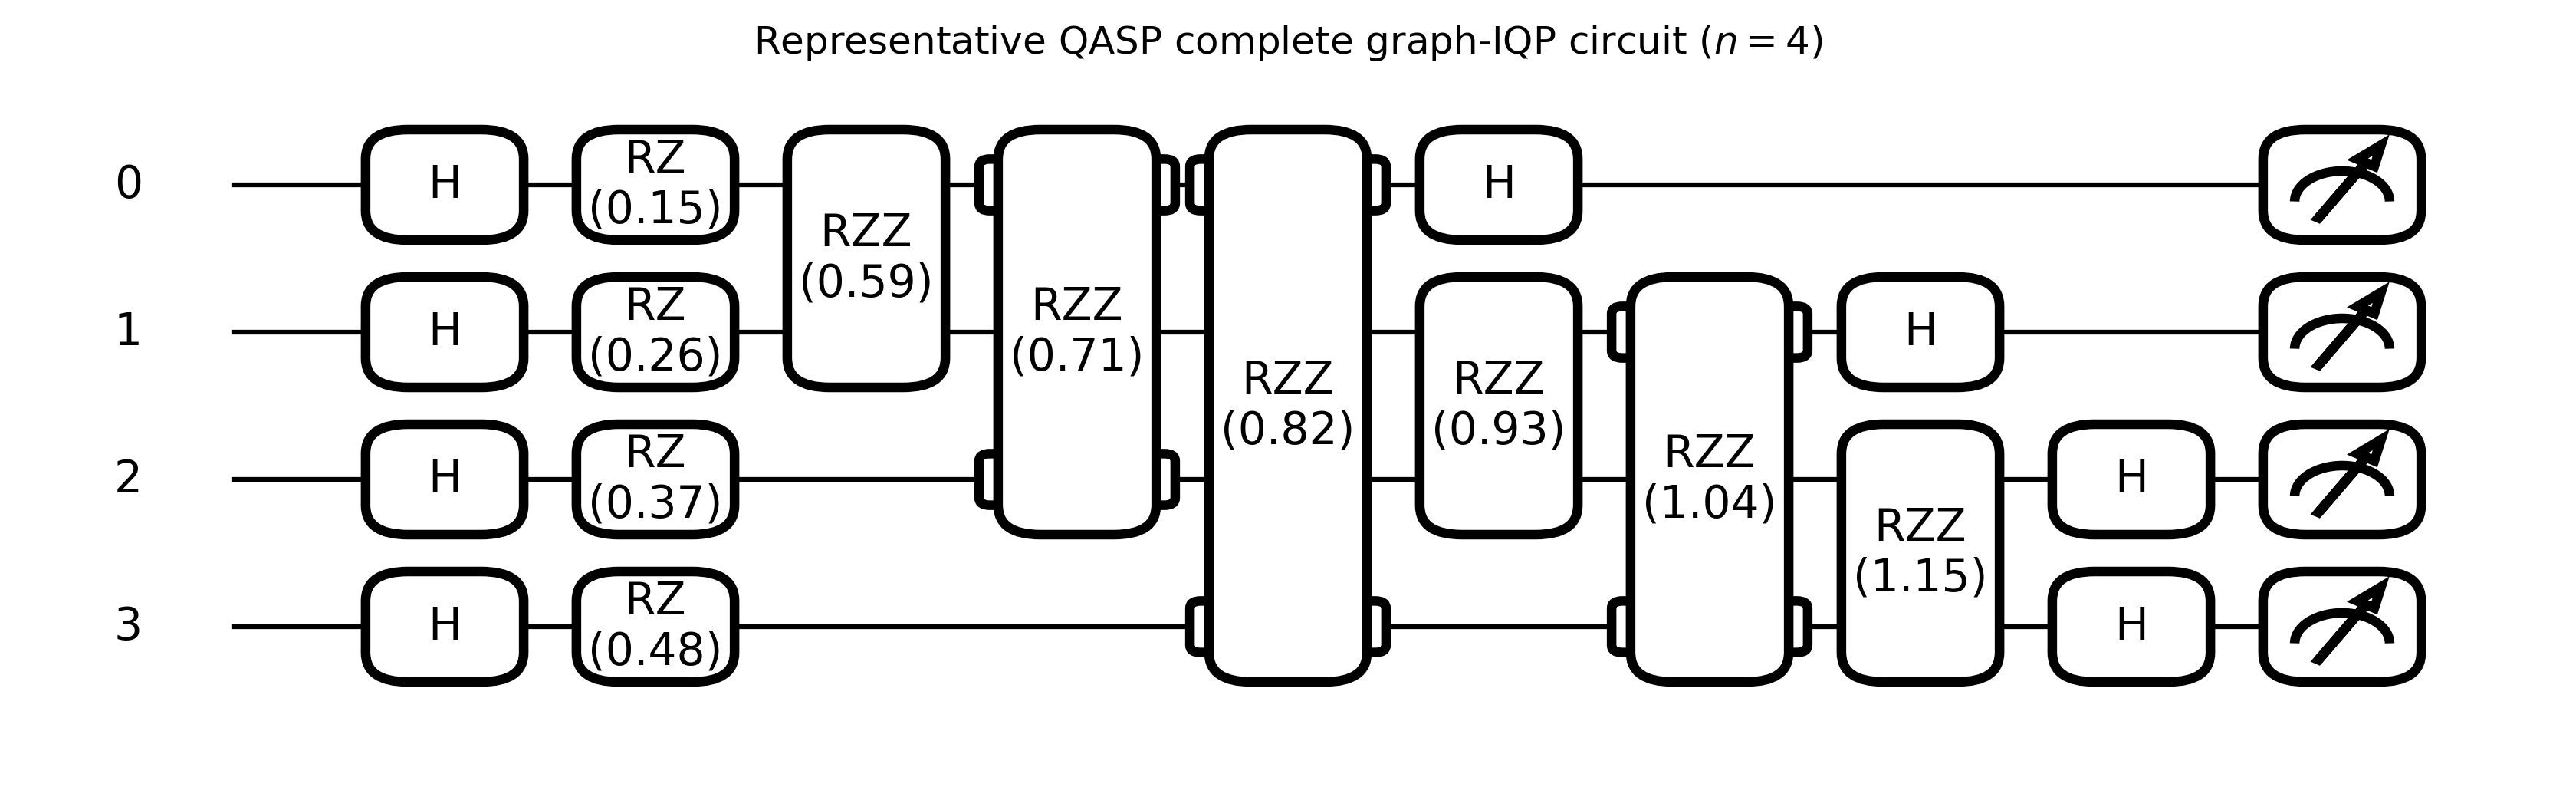

Saved ./tests/results/iqp_majority_all_to_all_variance/figures/representative_qasp_complete_iqp_n4.png


In [3]:
representative_builder, representative_ansatz, representative_qnode, representative_p = build_qasp_complete_iqp(4)
representative_theta = np.linspace(0.15, 1.15, representative_p)
circuit_figure, _ = qml.draw_mpl(representative_qnode, decimals=2)(
    params=representative_theta
)
circuit_figure.set_size_inches(11.0, 3.2)
circuit_figure.set_dpi(FIGURE_DPI)
circuit_figure.suptitle(
    r"Representative QASP complete graph-IQP circuit ($n=4$)",
    y=1.02,
)
circuit_figure.tight_layout()
circuit_png = FIGURES_DIR / "representative_qasp_complete_iqp_n4.png"
circuit_figure.savefig(circuit_png, dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()
print(f"Saved {circuit_png}")

<a id="monte-carlo-experiment"></a>
## Monte Carlo experiment

For every qubit count, draw 2,000 independent full parameter vectors with
each angle distributed as \(\operatorname{Unif}[-\pi,\pi]\). The table
reports the unbiased sample variance and the plug-in Monte Carlo standard
error computed from the empirical fourth central moment.

In [4]:
summary_rows = []
raw_rows = []
total_start = time.perf_counter()

for n in QUBITS:
    _, ansatz, qnode, n_parameters = build_qasp_complete_iqp(n)
    mask = majority_zero_mask(n)
    seed = BASE_SEED + n
    rng = np.random.default_rng(seed)
    parameter_samples = rng.uniform(
        -np.pi, np.pi, size=(N_SAMPLES, n_parameters)
    )
    action_zero = np.empty(N_SAMPLES, dtype=np.float64)
    start = time.perf_counter()

    for sample_index, theta in enumerate(parameter_samples):
        basis_probabilities = np.asarray(qnode(params=theta), dtype=np.float64)
        action_zero[sample_index] = basis_probabilities @ mask

    seconds = time.perf_counter() - start
    empirical_variance, mc_se = variance_mc_se(action_zero)
    theory = theoretical_variance(n)
    p = majority_bin_fraction(n)

    summary_rows.append({
        "n_qubits": n,
        "n_samples": N_SAMPLES,
        "seed": seed,
        "n_single_qubit_RZ": n,
        "n_RZZ_edges": len(ansatz.edges),
        "n_parameters": n_parameters,
        "action_0_basis_states": int(mask.sum()),
        "action_1_basis_states": int((1.0 - mask).sum()),
        "theory_mean": p,
        "sample_mean": action_zero.mean(),
        "mean_error": action_zero.mean() - p,
        "theory_variance": theory,
        "empirical_variance": empirical_variance,
        "mc_se": mc_se,
        "two_mc_se": 2.0 * mc_se,
        "z_score": (empirical_variance - theory) / mc_se if mc_se > 0 else np.nan,
        "seconds": seconds,
    })
    raw_rows.extend(
        {"n_qubits": n, "sample": i, "pi_action_0": value}
        for i, value in enumerate(action_zero)
    )
    print(
        f"n={n:2d}: empirical={empirical_variance:.8e}, "
        f"theory={theory:.8e}, z={summary_rows[-1]['z_score']:+.2f}, "
        f"time={seconds:.1f}s"
    )

total_seconds = time.perf_counter() - total_start
summary_df = pd.DataFrame(summary_rows)
raw_df = pd.DataFrame(raw_rows)

summary_csv = RESULTS_DIR / "variance_summary.csv"
raw_csv = RESULTS_DIR / "action_probability_samples.csv"
summary_df.to_csv(summary_csv, index=False)
raw_df.to_csv(raw_csv, index=False)

display(summary_df.round({
    "theory_mean": 8,
    "sample_mean": 8,
    "mean_error": 8,
    "theory_variance": 10,
    "empirical_variance": 10,
    "mc_se": 10,
    "z_score": 3,
    "seconds": 2,
}))
print(f"Total native-QASP simulation time: {total_seconds:.1f}s")
print(f"Saved {summary_csv}")
print(f"Saved {raw_csv}")

n= 4: empirical=1.37190290e-02, theory=1.34277344e-02, z=+0.60, time=1.1s


n= 6: empirical=3.60312644e-03, theory=3.52478027e-03, z=+0.54, time=1.6s


n= 8: empirical=8.60013100e-04, theory=9.03546810e-04, z=-1.08, time=2.5s


n=10: empirical=2.41789500e-04, theory=2.29354948e-04, z=+0.97, time=4.0s


n=12: empirical=5.99835222e-05, theory=5.79291373e-05, z=+0.53, time=7.1s


n=14: empirical=1.39792887e-05, theory=1.45892518e-05, z=-0.71, time=13.2s


n=16: empirical=3.43061779e-06, theory=3.66758215e-06, z=-0.89, time=40.1s


,n_qubits,n_samples,seed,n_single_qubit_RZ,n_RZZ_edges,n_parameters,action_0_basis_states,action_1_basis_states,theory_mean,sample_mean,mean_error,theory_variance,empirical_variance,mc_se,two_mc_se,z_score,seconds
0,4,2000,20261026,4,6,10,11,5,0.687500,0.683590,-0.003910,0.013428,0.013719,4.817267e-04,9.634534e-04,0.605,1.07
1,6,2000,20261028,6,15,21,42,22,0.656250,0.655793,-0.000457,0.003525,0.003603,1.451139e-04,2.902278e-04,0.540,1.63
2,8,2000,20261030,8,28,36,163,93,0.636719,0.637662,0.000943,0.000904,0.000860,4.030240e-05,8.060475e-05,-1.080,2.45
3,10,2000,20261032,10,45,55,638,386,0.623047,0.623393,0.000346,0.000229,0.000242,1.275640e-05,2.551284e-05,0.975,3.95
4,12,2000,20261034,12,66,78,2510,1586,0.612793,0.612713,-0.000080,0.000058,0.000060,3.879200e-06,7.758320e-06,0.530,7.06
5,14,2000,20261036,14,91,105,9908,6476,0.604736,0.604859,0.000122,0.000015,0.000014,8.547000e-07,1.709435e-06,-0.714,13.16
6,16,2000,20261038,16,120,136,39203,26333,0.598190,0.598273,0.000082,0.000004,0.000003,2.669000e-07,5.338586e-07,-0.888,40.06


Total native-QASP simulation time: 69.4s
Saved ./tests/results/iqp_majority_all_to_all_variance/variance_summary.csv
Saved ./tests/results/iqp_majority_all_to_all_variance/action_probability_samples.csv


<a id="variance-plot"></a>
## Variance plot

Points are native-QASP Monte Carlo estimates and error bars are twice the
estimated Monte Carlo standard error. The solid curve is the exact
complete-graph rank/light-cone prediction. The dotted curve
\(2^{-n}/4\) is the balanced-bin asymptotic reference.

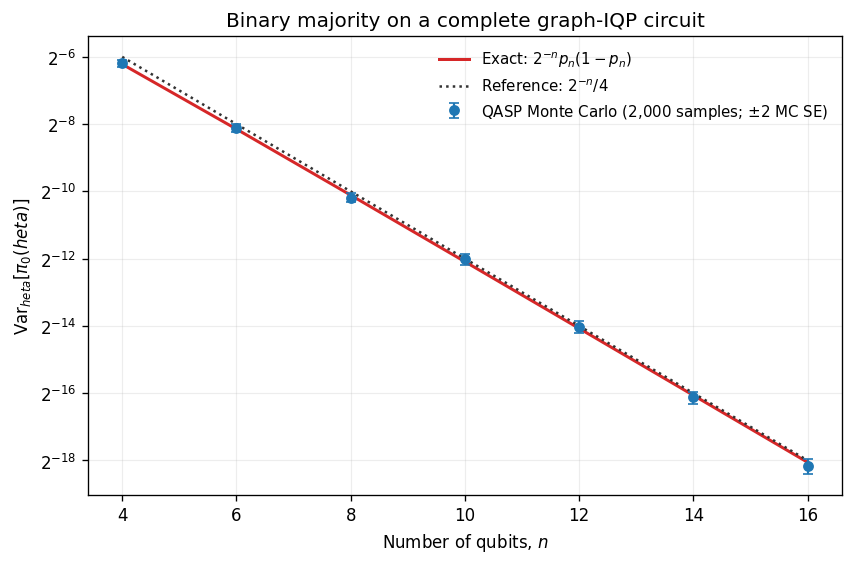

Saved ./tests/results/iqp_majority_all_to_all_variance/figures/majority_complete_iqp_variance.png
Saved ./tests/results/iqp_majority_all_to_all_variance/figures/majority_complete_iqp_variance.pdf


In [5]:
figure, axis = plt.subplots(figsize=(7.0, 4.6), constrained_layout=True)
x = summary_df["n_qubits"].to_numpy()
empirical = summary_df["empirical_variance"].to_numpy()
theory = summary_df["theory_variance"].to_numpy()
error = 2.0 * summary_df["mc_se"].to_numpy()
reference = 0.25 * np.power(2.0, -x)

axis.errorbar(
    x,
    empirical,
    yerr=error,
    fmt="o",
    markersize=5.5,
    capsize=3,
    color="#1f77b4",
    ecolor="#1f77b4",
    linewidth=1.3,
    label=r"QASP Monte Carlo ($2{,}000$ samples; $\pm2$ MC SE)",
    zorder=3,
)
axis.plot(
    x,
    theory,
    "-",
    color="#d62728",
    linewidth=1.8,
    label=r"Exact: $2^{-n}p_n(1-p_n)$",
)
axis.plot(
    x,
    reference,
    ":",
    color="#333333",
    linewidth=1.5,
    label=r"Reference: $2^{-n}/4$",
)
axis.set_yscale("log", base=2)
axis.set_xticks(QUBITS)
axis.set_xlabel("Number of qubits, $n$")
axis.set_ylabel(r"$\mathrm{Var}_{	heta}[\pi_0(	heta)]$")
axis.set_title(r"Binary majority on a complete graph-IQP circuit")
axis.grid(True, which="both", alpha=0.22, linewidth=0.7)
axis.legend(frameon=False, loc="upper right")

plot_png = FIGURES_DIR / "majority_complete_iqp_variance.png"
plot_pdf = FIGURES_DIR / "majority_complete_iqp_variance.pdf"
figure.savefig(plot_png, dpi=FIGURE_DPI, bbox_inches="tight")
figure.savefig(plot_pdf, bbox_inches="tight")
plt.show()
print(f"Saved {plot_png}")
print(f"Saved {plot_pdf}")

<a id="validation-and-reproducibility"></a>
## Validation and reproducibility

The checks below verify the complete-graph gate and parameter counts,
normalization and support of every action probability, agreement with the
exact prediction relative to Monte Carlo uncertainty, and hashes of all
durable outputs.

In [6]:
assert len(summary_df) == len(QUBITS)
assert len(raw_df) == len(QUBITS) * N_SAMPLES
assert np.isfinite(summary_df.select_dtypes(include=[np.number]).to_numpy()).all()
assert raw_df["pi_action_0"].between(-1e-10, 1.0 + 1e-10).all()
assert (
    summary_df["n_RZZ_edges"]
    == summary_df["n_qubits"] * (summary_df["n_qubits"] - 1) // 2
).all()
assert (
    summary_df["n_parameters"]
    == summary_df["n_qubits"] + summary_df["n_RZZ_edges"]
).all()

within_five_mc_se = (
    np.abs(summary_df["empirical_variance"] - summary_df["theory_variance"])
    <= 5.0 * summary_df["mc_se"]
)
assert within_five_mc_se.all(), summary_df.loc[~within_five_mc_se]

def git_text(*args):
    return subprocess.check_output(
        ["git", *args], cwd=PROJECT_ROOT, text=True, stderr=subprocess.DEVNULL
    ).strip()

metadata = {
    "experiment": "binary majority policy variance on complete graph-IQP",
    "notebook": str(NOTEBOOK_DIR / "iqp_majority_all_to_all_variance.ipynb"),
    "results_directory": str(RESULTS_DIR),
    "qubits": QUBITS,
    "n_samples_per_qubit_count": N_SAMPLES,
    "base_seed": BASE_SEED,
    "angle_distribution": "independent Uniform[-pi, pi]",
    "policy": "majority-modulo",
    "n_actions": 2,
    "action": 0,
    "tie_rule": "action 0 when Hamming weight equals n/2",
    "circuit": {
        "qasp_template": "IQPAnsatz",
        "n_layers": 1,
        "single_qubit_gates": "RZ on every qubit",
        "two_qubit_gates": "one PauliRot(ZZ) for every unordered pair i<j",
        "imprimitive_pattern": "all_to_all",
        "initial_and_final_gates": "Hadamard on every qubit",
    },
    "execution": {
        "backend": "native QASP CircuitBuilder / PennyLane lightning.qubit",
        "measurement": "exact computational-basis probabilities",
        "shots": None,
        "diff_method": None,
        "custom_statevector_simulator": False,
    },
    "statistic": "unbiased sample variance of action-0 probability",
    "uncertainty": "plug-in Monte Carlo SE from empirical fourth central moment",
    "theory": "2^(-n) p_n (1-p_n), with deterministic-tie majority bin fraction p_n",
    "total_simulation_seconds": total_seconds,
    "software": {
        "python": sys.version,
        "platform": platform.platform(),
        "qasp": QASP_VERSION,
        "pennylane": qml.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "matplotlib": mpl.__version__,
    },
    "git": {
        "branch": git_text("branch", "--show-current"),
        "commit": git_text("rev-parse", "HEAD"),
        "dirty": bool(git_text("status", "--porcelain")),
    },
}
metadata_path = RESULTS_DIR / "metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2) + "\n")

durable_files = [summary_csv, raw_csv, plot_png, plot_pdf, circuit_png, metadata_path]
manifest_rows = []
for path in durable_files:
    manifest_rows.append({
        "path": str(path.relative_to(RESULTS_DIR)),
        "bytes": path.stat().st_size,
        "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
    })
manifest_df = pd.DataFrame(manifest_rows)
manifest_path = RESULTS_DIR / "manifest.json"
manifest_path.write_text(json.dumps(manifest_rows, indent=2) + "\n")
display(manifest_df)

print(
    "All checks passed. Maximum |variance z-score| = "
    f"{summary_df['z_score'].abs().max():.3f}."
)
print(
    "The measured action-probability variance follows the complete-graph "
    "prediction and decays exponentially with n."
)

,path,bytes,sha256
0,variance_summary.csv,1704,9383a4dd2e8f85d3fc9986f66f0e6c12496fb75be69043...
1,action_probability_samples.csv,362669,73810b6e7750dcd1d45e9a74f874a92502d38dc42ef2c5...
2,figures/majority_complete_iqp_variance.png,149735,8e463f429b392fe01e1a4e5dce151344ba421c06e76196...
3,figures/majority_complete_iqp_variance.pdf,21569,e182e32d363f101c1f1eebff2800c5db46d03b8b183db0...
4,figures/representative_qasp_complete_iqp_n4.png,141010,cd937d32c739cd317b3f24e2d3755142449cdb54c41fd1...
5,metadata.json,1819,2124e9e26f9622f0d1580d4056a7770163a9801e1fd451...


All checks passed. Maximum |variance z-score| = 1.080.
The measured action-probability variance follows the complete-graph prediction and decays exponentially with n.
